# The Real Price — analysis notebook
**What my spending cost in hours of my life.**

Data: 707 **simulated** transactions (1 Jan – 25 Oct 2026), enriched by `scripts/enrich.py`.
Every money figure is also shown in **hours of work** at £12.71/hour (UK National Living Wage from April 2026).

Structure: **WHAT → WHEN → WHY → HOW → creative layer → SOLUTION**.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

WAGE = 12.71
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COL = {"Essential": "#2a7f62", "Investment": "#2f6fb5", "Lifestyle": "#d9a400", "Leakage": "#c8442f"}

df = pd.read_csv("../data/processed/transactions_enriched.csv", parse_dates=["date"])
spend = df[df.direction == "Debit"].copy()
refunds = df[(df.direction == "Credit") & (df.category != "Income")]
income = df[(df.direction == "Credit") & (df.category == "Income")]
disc = spend[spend.spend_type.isin(["Lifestyle", "Leakage"])]           # discretionary spending
disc_nosub = disc[disc.category != "Subscriptions"]                      # subscriptions renew at ~04:30 automatically
metrics = {}
print(len(df), "rows |", df.date.min().date(), "to", df.date.max().date())
print("Spending rows:", len(spend), "| refunds:", len(refunds), "| income rows:", len(income))

707 rows | 2026-01-01 to 2026-10-25
Spending rows: 685 | refunds: 5 | income rows: 17


## 1. WHAT — where does the money go?

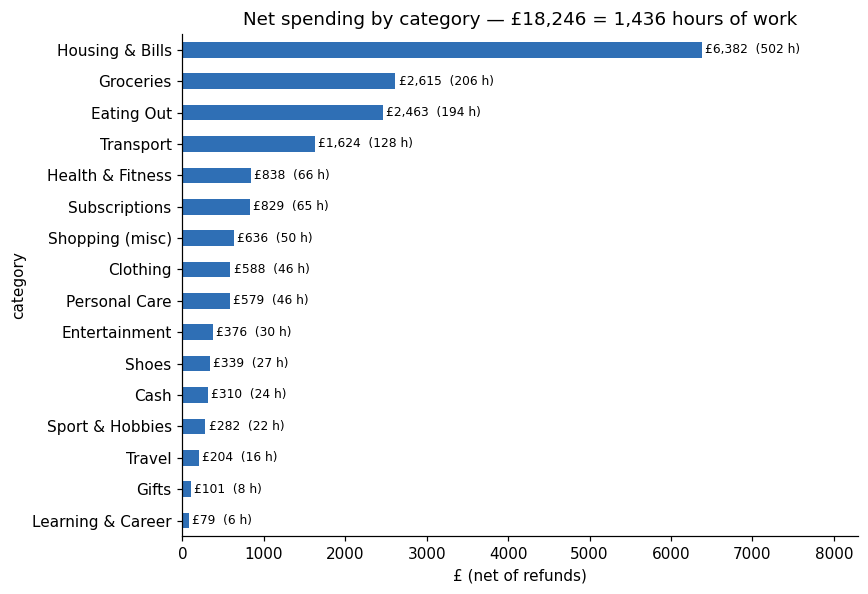

Total spent: £18,245.78 = 1,436 hours of work


In [2]:
net = spend.groupby("category").amount_gbp.sum().sub(refunds.groupby("category").amount_gbp.sum(), fill_value=0)
net = net.sort_values()
total = net.sum()
metrics["total_spend"] = round(total, 2)
metrics["total_hours"] = round(total / WAGE, 1)
metrics["months"] = 9.8

ax = net.plot.barh(figsize=(8, 5.5), color="#2f6fb5")
for i, v in enumerate(net):
    ax.text(v + 40, i, f"£{v:,.0f}  ({v/WAGE:,.0f} h)", va="center", fontsize=8)
ax.set_title(f"Net spending by category — £{total:,.0f} = {total/WAGE:,.0f} hours of work")
ax.set_xlabel("£ (net of refunds)"); ax.set_xlim(0, net.max() * 1.3)
plt.tight_layout(); plt.savefig("../images/01_category.png"); plt.show()
print(f"Total spent: £{total:,.2f} = {total/WAGE:,.0f} hours of work")

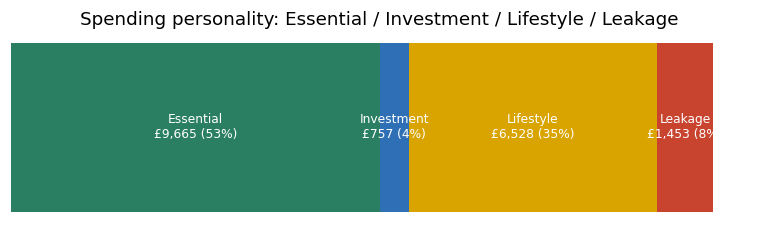

spend_type
Essential     9665.26
Investment     756.83
Lifestyle     6528.26
Leakage       1452.65


,count,sum
merchant,,
Trainline,50,1465.40
Uber Eats,34,779.85
Aldi,24,754.32
Tesco,22,642.23
Amazon,25,636.18


In [3]:
st = spend.groupby("spend_type").amount_gbp.sum().reindex(["Essential", "Investment", "Lifestyle", "Leakage"])
metrics["spend_type"] = {k: round(v, 2) for k, v in st.items()}
fig, ax = plt.subplots(figsize=(7, 2.2))
left = 0
for k, v in st.items():
    ax.barh(0, v, left=left, color=COL[k]); ax.text(left + v / 2, 0, f"{k}\n£{v:,.0f} ({v/st.sum():.0%})", ha="center", va="center", color="white", fontsize=8)
    left += v
ax.axis("off"); ax.set_title("Spending personality: Essential / Investment / Lifestyle / Leakage")
plt.tight_layout(); plt.savefig("../images/02_spend_type.png"); plt.show()
print(st.round(2).to_string())
top_merch = spend[spend.subcategory != "Rent"].groupby("merchant").amount_gbp.agg(["count", "sum"]).sort_values("sum", ascending=False).head(5)
metrics["top_merchants"] = [{"merchant": m, "spend": round(r["sum"], 2), "count": int(r["count"])} for m, r in top_merch.iterrows()]
top_merch

## 2. WHEN — month, time of day, weekday

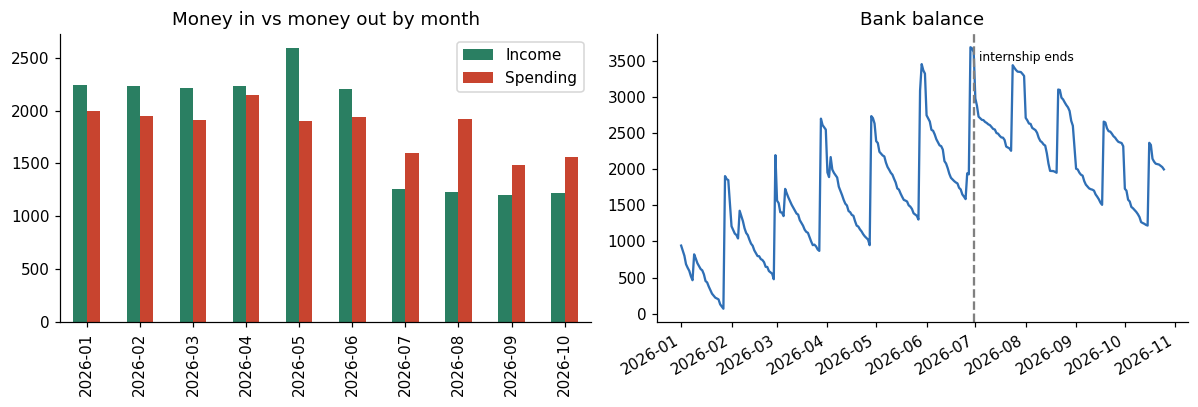

Internship (Jan-Jun): income £75.92/day | spending (excl. rent) £46.38/day
After internship (Jul-Oct): income £41.92/day | spending (excl. rent) £36.40/day
Income fell 44.8% per day after the internship; spending fell only 21.5%.


In [4]:
m = df.assign(inc=np.where((df.direction == "Credit") & (df.category == "Income"), df.amount_gbp, 0),
             out=np.where(df.direction == "Debit", df.amount_gbp, 0)).groupby("month")[["inc", "out"]].sum()
bal = df.groupby("date").balance_gbp.last()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
m.plot.bar(ax=ax[0], color=["#2a7f62", "#c8442f"]); ax[0].set_title("Money in vs money out by month"); ax[0].legend(["Income", "Spending"]); ax[0].set_xlabel("")
bal.plot(ax=ax[1], color="#2f6fb5"); ax[1].axvline(pd.Timestamp("2026-06-30"), ls="--", color="grey"); ax[1].text(pd.Timestamp("2026-07-03"), bal.max() * 0.95, "internship ends", fontsize=8)
ax[1].set_title("Bank balance"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig("../images/03_month_balance.png"); plt.show()

days = {"Internship (Jan-Jun)": 181, "After internship (Jul-Oct)": 117}
per = spend[spend.subcategory != "Rent"].groupby("period").amount_gbp.sum()
inc = income.groupby("period").amount_gbp.sum()
for p, d in days.items():
    print(f"{p}: income £{inc[p]/d:,.2f}/day | spending (excl. rent) £{per[p]/d:,.2f}/day")
metrics["income_drop_pct"] = round(100 * (1 - (inc["After internship (Jul-Oct)"] / 117) / (inc["Internship (Jan-Jun)"] / 181)), 1)
metrics["spend_drop_pct"] = round(100 * (1 - (per["After internship (Jul-Oct)"] / 117) / (per["Internship (Jan-Jun)"] / 181)), 1)
metrics["peak_balance"] = {"date": str(bal.idxmax().date()), "gbp": round(bal.max(), 2)}
metrics["end_balance"] = round(bal.iloc[-1], 2)
print(f"Income fell {metrics['income_drop_pct']}% per day after the internship; spending fell only {metrics['spend_drop_pct']}%.")

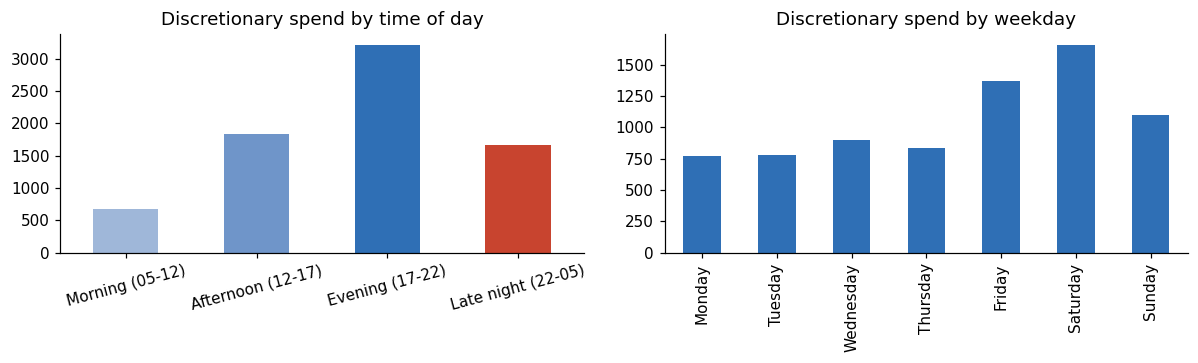

Most expensive hour: 20:00 (£810). Late-night tax (22:00-05:00): £1,672 = 132 hours


In [5]:
order = ["Morning (05-12)", "Afternoon (12-17)", "Evening (17-22)", "Late night (22-05)"]
tb = disc_nosub.groupby("time_band").amount_gbp.sum().reindex(order)
wd = disc_nosub.groupby("weekday").amount_gbp.sum().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
tb.plot.bar(ax=ax[0], color=["#9fb7d9", "#6f95c9", "#2f6fb5", "#c8442f"]); ax[0].set_title("Discretionary spend by time of day"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=15)
wd.plot.bar(ax=ax[1], color="#2f6fb5"); ax[1].set_title("Discretionary spend by weekday"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig("../images/04_time_weekday.png"); plt.show()
hour = disc_nosub.groupby("hour").amount_gbp.sum()
metrics["most_expensive_hour"] = int(hour.idxmax())
metrics["late_night_spend"] = round(tb["Late night (22-05)"], 2)
print(f"Most expensive hour: {hour.idxmax()}:00 (£{hour.max():,.0f}). Late-night tax (22:00-05:00): £{tb['Late night (22-05)']:,.0f} = {tb['Late night (22-05)']/WAGE:,.0f} hours")

## 3. WHY — what triggers spending?
### 3a. The payday effect
Average discretionary spend **per calendar day** (days with no spending count as £0), by days since the last payday.
Is the jump real or chance? A **permutation test** (no extra libraries needed): shuffle which days are 'just after payday' 10,000 times and see how often a gap this big appears by luck.

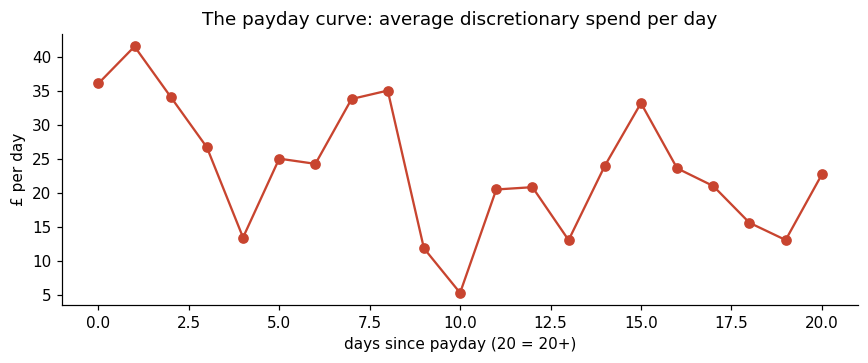

0-3 days after payday: £34.90/day vs £21.53/day otherwise (1.62x). Permutation p = 0.0008


In [6]:
cal = pd.DataFrame({"date": pd.date_range("2026-01-09", "2026-10-25")})
paydays = sorted(income.date.unique())
cal["dsp"] = cal.date.apply(lambda d: (d - max(p for p in paydays if p <= d)).days)
daily = disc_nosub.groupby("date").amount_gbp.sum()
cal["spend"] = cal.date.map(daily).fillna(0)
curve = cal.groupby(cal.dsp.clip(upper=20)).spend.mean()
ax = curve.plot(marker="o", figsize=(8, 3.4), color="#c8442f"); ax.set_title("The payday curve: average discretionary spend per day")
ax.set_xlabel("days since payday (20 = 20+)"); ax.set_ylabel("£ per day")
plt.tight_layout(); plt.savefig("../images/05_payday_curve.png"); plt.show()

post = cal.spend[cal.dsp <= 3]; rest = cal.spend[cal.dsp > 3]
gap = post.mean() - rest.mean()
rng = np.random.default_rng(2026); vals = cal.spend.to_numpy().copy(); n = len(post); hits = 0
for _ in range(10_000):
    rng.shuffle(vals)
    hits += (vals[:n].mean() - vals[n:].mean()) >= gap
p = hits / 10_000
metrics["payday"] = {"post_per_day": round(post.mean(), 2), "rest_per_day": round(rest.mean(), 2), "ratio": round(post.mean() / rest.mean(), 2), "p_value": p}
print(f"0-3 days after payday: £{post.mean():.2f}/day vs £{rest.mean():.2f}/day otherwise ({post.mean()/rest.mean():.2f}x). Permutation p = {p:.4f}")

### 3b. Shift days and takeaways

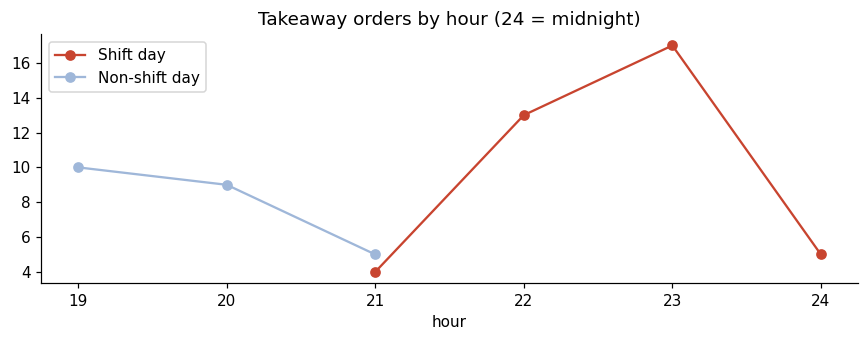

           orders   spend
shift_day                
False          24  546.07
True           39  902.92
Takeaways after 21:00 on shift days: 39 orders, £902.92 = 71 hours of work


In [7]:
tk = spend[spend.subcategory == "Takeaway delivery"]
by = tk.groupby("shift_day").agg(orders=("amount_gbp", "size"), spend=("amount_gbp", "sum"))
shift_days = cal.date.apply(lambda d: d in set(df.loc[df.shift_day, "date"])).sum()
fig, ax = plt.subplots(figsize=(8, 3.2))
for flag, c, lab in [(True, "#c8442f", "Shift day"), (False, "#9fb7d9", "Non-shift day")]:
    tk[tk.shift_day == flag].hour.replace({0: 24}).value_counts().sort_index().plot(ax=ax, marker="o", color=c, label=lab)
ax.set_title("Takeaway orders by hour (24 = midnight)"); ax.set_xlabel("hour"); ax.legend()
plt.tight_layout(); plt.savefig("../images/06_takeaway_hours.png"); plt.show()
late_shift = tk[tk.shift_day & ((tk.hour >= 21) | (tk.hour < 5))]
metrics["takeaway"] = {"total": round(tk.amount_gbp.sum(), 2), "orders": int(len(tk)),
                       "late_shift_orders": int(len(late_shift)), "late_shift_spend": round(late_shift.amount_gbp.sum(), 2)}
print(by)
print(f"Takeaways after 21:00 on shift days: {len(late_shift)} orders, £{late_shift.amount_gbp.sum():,.2f} = {late_shift.amount_gbp.sum()/WAGE:,.0f} hours of work")

## 4. HOW — does the way I pay change what I spend?

In [8]:
pm = disc_nosub.groupby("payment_method").amount_gbp.agg(["count", "sum", "mean"]).sort_values("sum", ascending=False)
gro = spend[spend.category == "Groceries"].groupby("subcategory").amount_gbp.agg(["count", "sum", "mean"])
metrics["apple_pay_share"] = round(100 * pm.loc["Apple Pay", "sum"] / pm["sum"].sum(), 1)
metrics["topup"] = {"trips": int(gro.loc["Top-up shop", "count"]), "spend": round(gro.loc["Top-up shop", "sum"], 2),
                    "share_of_groceries": round(100 * gro.loc["Top-up shop", "sum"] / gro["sum"].sum(), 1)}
print(pm.round(2)); print(); print(gro.round(2))
print(f"Apple Pay = {metrics['apple_pay_share']}% of discretionary spend. Top-ups = {metrics['topup']['share_of_groceries']}% of grocery money across {metrics['topup']['trips']} trips.")
late_online = disc_nosub[disc_nosub.channel.isin(["Online", "App"]) & ((disc_nosub.hour >= 22) | (disc_nosub.hour < 5))]
asos_ref = refunds[refunds.merchant == "ASOS"].amount_gbp.sum()
metrics["late_online"] = round(late_online.amount_gbp.sum(), 2)
print(f"Late-night online/app spend: £{late_online.amount_gbp.sum():,.2f}. ASOS refunds: £{asos_ref:,.2f}")

                count      sum    mean
payment_method                        
Apple Pay         375  4725.40   12.60
Debit card         57  2256.21   39.58
Cash               10   310.00   31.00
Bank transfer       1   120.00  120.00

             count      sum   mean
subcategory                       
Top-up shop     81   879.47  10.86
Weekly shop     52  1735.30  33.37
Apple Pay = 63.8% of discretionary spend. Top-ups = 33.6% of grocery money across 81 trips.
Late-night online/app spend: £1,587.17. ASOS refunds: £157.22


## 5. Creative layer
### 5a. Protein economics — £ per 20 g of protein
**Assumptions (stated, not measured):** a bulk online order ≈ 2.5 kg whey ≈ 2,000 g protein; an in-store small tub ≈ 450 g ≈ 360 g protein; one bar or shake ≈ 20 g protein at the amount paid per transaction ÷ 2 items.

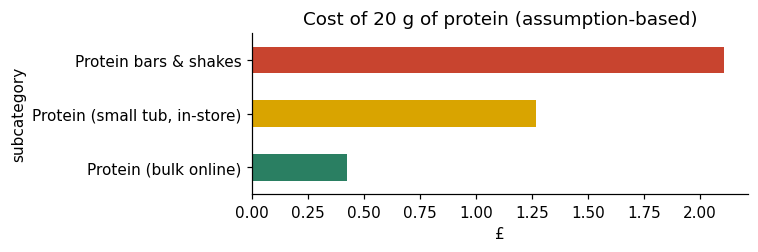

,count,mean,sum,gbp_per_20g
subcategory,,,,
Protein (bulk online),8,42.48,339.86,0.42
"Protein (small tub, in-store)",7,22.85,159.93,1.27
Protein bars & shakes,21,4.22,88.64,2.11


In [9]:
prot = spend[spend.subcategory.str.startswith("Protein")]
g = prot.groupby("subcategory").amount_gbp.agg(["count", "mean", "sum"])
grams = {"Protein (bulk online)": 2000, "Protein (small tub, in-store)": 360, "Protein bars & shakes": 40}
g["gbp_per_20g"] = g.apply(lambda r: r["mean"] / grams[r.name] * 20, axis=1)
metrics["protein_per_20g"] = {k: round(v, 2) for k, v in g.gbp_per_20g.items()}
ax = g.gbp_per_20g.sort_values().plot.barh(figsize=(7, 2.4), color=["#2a7f62", "#d9a400", "#c8442f"])
ax.set_title("Cost of 20 g of protein (assumption-based)"); ax.set_xlabel("£"); plt.tight_layout(); plt.savefig("../images/07_protein.png"); plt.show()
g.round(2)

### 5b. Hours of life — the headline numbers

In [10]:
hours = net.div(WAGE).sort_values(ascending=False).round(0)
fun = {"Takeaways after shifts": metrics["takeaway"]["late_shift_spend"], "Late-night spending": metrics["late_night_spend"],
       "Top-up shops": metrics["topup"]["spend"], "All subscriptions": round(spend[spend.category == "Subscriptions"].amount_gbp.sum(), 2)}
for k, v in fun.items():
    print(f"{k:<24} £{v:>8,.2f} = {v/WAGE:>5.0f} hours = {v/WAGE/7.5:>4.1f} shifts of 7.5 h")
metrics["hours_headlines"] = {k: round(v / WAGE, 1) for k, v in fun.items()}
hours.head(6)

Takeaways after shifts   £  902.92 =    71 hours =  9.5 shifts of 7.5 h
Late-night spending      £1,671.53 =   132 hours = 17.5 shifts of 7.5 h
Top-up shops             £  879.47 =    69 hours =  9.2 shifts of 7.5 h
All subscriptions        £  829.26 =    65 hours =  8.7 shifts of 7.5 h


category
Housing & Bills     502.0
Groceries           206.0
Eating Out          194.0
Transport           128.0
Health & Fitness     66.0
Subscriptions        65.0
Name: amount_gbp, dtype: float64

## 6. SOLUTION — five rules and what they are worth
Each rule has a stated assumption. Savings are projected for the **67 days to 31 Dec 2026** and per year, using the post-internship rate (Jul–25 Oct, 117 days) where behaviour matters.

In [11]:
after = spend[spend.period == "After internship (Jul-Oct)"]
D_AFTER, D_LEFT = 117, 67
rules = []
z = spend[spend.merchant.isin(["Disney+", "Google One"])].groupby("merchant").amount_gbp.max().sum()
rules.append(("Cancel zombie & duplicate subscriptions (Disney+, Google One)", z * 12 / 365))
lt = after[(after.subcategory == "Takeaway delivery") & after.shift_day & ((after.hour >= 21) | (after.hour < 5))]
rules.append(("Shift-day meal prep: replace 3 in 4 late takeaways with a £3 prepared meal", 0.75 * (lt.amount_gbp - 3).clip(lower=0).sum() / D_AFTER))
tu = after[after.subcategory == "Top-up shop"].amount_gbp.sum()
rules.append(("Halve top-up trips; buy it in the weekly shop (assume 25% cheaper there)", 0.5 * tu * 0.25 / D_AFTER))
tub = spend[spend.subcategory == "Protein (small tub, in-store)"].amount_gbp.sum()
rules.append(("Protein: bulk only (in-store tubs cost ~3x more per gram)", tub * (1 - metrics["protein_per_20g"]["Protein (bulk online)"] / metrics["protein_per_20g"]["Protein (small tub, in-store)"]) / 298))
lo = after[after.channel.isin(["Online", "App"]) & ((after.hour >= 22) | (after.hour < 5)) & after.category.isin(["Clothing", "Shopping (misc)", "Entertainment"])].amount_gbp.sum()
rules.append(("24-hour basket rule for late-night online shopping (assume half never bought)", 0.5 * lo / D_AFTER))
plan = pd.DataFrame(rules, columns=["rule", "gbp_per_day"])
plan["by_31_dec"] = (plan.gbp_per_day * D_LEFT).round(2)
plan["per_year"] = (plan.gbp_per_day * 365).round(2)
plan["hours_per_year"] = (plan.per_year / WAGE).round(0)
metrics["plan"] = plan[["rule", "by_31_dec", "per_year", "hours_per_year"]].to_dict("records")
metrics["plan_total_year"] = round(plan.per_year.sum(), 2)
metrics["plan_total_dec"] = round(plan.by_31_dec.sum(), 2)
print(f"Total: £{plan.by_31_dec.sum():,.2f} by 31 Dec | £{plan.per_year.sum():,.2f} a year = {plan.per_year.sum()/WAGE:,.0f} hours of work")
plan.round(2)

Total: £305.56 by 31 Dec | £1,664.57 a year = 131 hours of work


,rule,gbp_per_day,by_31_dec,per_year,hours_per_year
0,Cancel zombie & duplicate subscriptions (Disne...,0.26,17.58,95.76,8.0
1,Shift-day meal prep: replace 3 in 4 late takea...,2.75,184.08,1002.81,79.0
2,Halve top-up trips; buy it in the weekly shop ...,0.40,26.74,145.68,11.0
3,Protein: bulk only (in-store tubs cost ~3x mor...,0.36,24.07,131.11,10.0
4,24-hour basket rule for late-night online shop...,0.79,53.09,289.21,23.0


In [12]:
# Savings runway: at the post-internship net rate, when does the balance reach zero - with and without the plan?
net_day = (income[income.period == "After internship (Jul-Oct)"].amount_gbp.sum() - after.amount_gbp.sum()) / D_AFTER
end = metrics["end_balance"]
runway = end / -net_day if net_day < 0 else None
runway_plan = end / -(net_day + plan.gbp_per_day.sum()) if net_day + plan.gbp_per_day.sum() < 0 else None
last = pd.Timestamp("2026-10-25")
metrics["runway"] = {"net_per_day": round(net_day, 2), "days": round(runway) if runway else None,
                     "zero_date": str((last + pd.Timedelta(days=runway)).date()) if runway else None,
                     "days_with_plan": round(runway_plan) if runway_plan else None,
                     "zero_date_with_plan": str((last + pd.Timedelta(days=runway_plan)).date()) if runway_plan else None}
print(metrics["runway"])
json.dump(metrics, open("../dashboard/metrics.json", "w"), indent=2, default=float)
print("metrics saved to dashboard/metrics.json")

{'net_per_day': np.float64(-14.13), 'days': 142, 'zero_date': '2027-03-15', 'days_with_plan': 209, 'zero_date_with_plan': '2027-05-21'}
metrics saved to dashboard/metrics.json


## Limitations
- **Simulated data** modelled on my lifestyle — the method is real, the transactions are not.
- One person, ~10 months; October is partial (handled with per-day figures).
- Spend types and the shift-day takeaway rule are my definitions (see `data/reference/spend_type_map.csv`).
- Protein and top-up savings rely on stated assumptions, not measured prices — the UK Basket Index project will replace the top-up assumption with real supermarket prices.
- The payday effect shows **association, not proof of cause**.